
# Project Introduction:

# Tech Job Market Insights Dashboard

## Project Overview
This project aims to analyze real-world technology job postings and build an interactive dashboard that provides insights into the global tech job market.

## Project Objectives
- Explore technology job postings from multiple countries.
- Identify the most in-demand technical skills.
- Analyze job titles, locations, and employment types.
- Explore salary information where available.
- Present key findings through an interactive dashboard.

## Dataset
Source: Hugging Face – Tech Job Postings Salary Dataset  
Dataset: `zalizedata/tech-job-postings-salary-dataset`

The dataset contains publicly collected job postings from multiple recruitment platforms.

**Data snapshot:** August 1, 2026.

## Tools & Technologies
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Streamlit

# Libraries & Setup

In [39]:
# Install required libraries
!pip install -q pandas numpy pyarrow matplotlib seaborn langdetect deep-translator

In [40]:
# Import libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from collections import Counter
from langdetect import detect, LangDetectException
from deep_translator import GoogleTranslator

import warnings
warnings.filterwarnings("ignore")

print("Libraries imported successfully!")

Libraries imported successfully!


# Load Dataset

In [41]:
# Dataset URL from Hugging Face

url = "https://huggingface.co/datasets/zalizedata/tech-job-postings-salary-dataset/resolve/main/data/S/jobs-00000-of-00001.parquet"

# Load dataset
df = pd.read_parquet(url)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [42]:
# Display first 5 rows

df.head()

,company_name,company_domain,company_industry,ats,ats_token,job_id,title,department,location_raw,country,...,employment_type,salary_min,salary_max,salary_currency,salary_period,salary_from_text,skills,posted_at,scraped_at,url
0,1mind,1mind.com,None,ashby,1mind,46a3c257-5c87-4e8b-925a-8d5b332307d9,AI System Engineer,Engineering,Remote - US; San Francisco,United States,...,full_time,175000.0,250000.0,USD,year,False,"[kubernetes, llm, machine-learning, python, ty...",2026-05-14T12:55:35.891+00:00,2026-08-01T01:09:37Z,https://jobs.ashbyhq.com/1mind/46a3c257-5c87-4...
1,1mind,1mind.com,None,ashby,1mind,3d939e24-b792-4663-9ae2-9e4c468c127e,Prompting Implementation Specialist,Engineering,Remote - US,United States,...,full_time,80000.0,150000.0,USD,year,False,"[customer-success, data-science, llm, nlp, pyt...",2026-07-06T16:22:59.783+00:00,2026-08-01T01:09:37Z,https://jobs.ashbyhq.com/1mind/3d939e24-b792-4...
2,1mind,1mind.com,None,ashby,1mind,5a6b1b8f-7ad0-4afd-8916-538eb18627d9,Superhuman (Agent) Architect,Customer Success,Remote - US,United States,...,full_time,125000.0,220000.0,USD,year,False,"[javascript, llm, nlp, project-management, pyt...",2026-04-29T20:41:53.244+00:00,2026-08-01T01:09:37Z,https://jobs.ashbyhq.com/1mind/5a6b1b8f-7ad0-4...
3,1mind,1mind.com,None,ashby,1mind,2b085917-8022-4e12-8a54-06de0722f091,AI Operations Lead,Marketing,Remote - US,United States,...,full_time,150000.0,165000.0,USD,year,False,"[communication, python]",2026-07-13T23:12:36.913+00:00,2026-08-01T01:09:37Z,https://jobs.ashbyhq.com/1mind/2b085917-8022-4...
4,1password,agilebits.com,None,ashby,1password,2951e57f-d0c1-4cdc-b0b7-ed62075aaf9a,"Senior Security Engineer, Incident Response",Technology,Remote (United States | Canada),None,...,full_time,NaN,NaN,None,None,False,"[machine-learning, nlp, project-management, py...",2025-12-23T02:12:18.679+00:00,2026-08-01T01:09:38Z,https://jobs.ashbyhq.com/1password/2951e57f-d0...


# Initial Data Inspection

In [43]:
# Check dataset dimensions

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 35417
Number of columns: 22


In [44]:
# Display column names

print(df.columns.tolist())

['company_name', 'company_domain', 'company_industry', 'ats', 'ats_token', 'job_id', 'title', 'department', 'location_raw', 'country', 'city', 'is_remote', 'employment_type', 'salary_min', 'salary_max', 'salary_currency', 'salary_period', 'salary_from_text', 'skills', 'posted_at', 'scraped_at', 'url']


In [45]:
# Check data types and non-null values

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35417 entries, 0 to 35416
Data columns (total 22 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   company_name      35417 non-null  object 
 1   company_domain    13842 non-null  object 
 2   company_industry  10257 non-null  object 
 3   ats               35417 non-null  object 
 4   ats_token         35417 non-null  object 
 5   job_id            35417 non-null  object 
 6   title             35417 non-null  object 
 7   department        30182 non-null  object 
 8   location_raw      35417 non-null  object 
 9   country           30442 non-null  object 
 10  city              25852 non-null  object 
 11  is_remote         35417 non-null  bool   
 12  employment_type   25509 non-null  object 
 13  salary_min        13931 non-null  float64
 14  salary_max        13931 non-null  float64
 15  salary_currency   13931 non-null  object 
 16  salary_period     13931 non-null  object

In [46]:
# Check missing values

missing_values = df.isnull().sum()

missing_values = missing_values[missing_values > 0].sort_values(
    ascending=False
)

print(missing_values)

company_industry    25160
company_domain      21575
salary_period       21486
salary_currency     21486
salary_max          21486
salary_min          21486
employment_type      9908
city                 9565
department           5235
country              4975
dtype: int64


In [47]:
# Statistical summary of numerical columns

df.describe()

,salary_min,salary_max
count,1.393100e+04,1.393100e+04
mean,2.054175e+05,2.885958e+05
std,2.966507e+06,4.134486e+06
min,0.000000e+00,0.000000e+00
25%,1.100000e+05,1.500000e+05
50%,1.472000e+05,2.000000e+05
75%,1.800000e+05,2.500000e+05
max,2.480000e+08,3.100000e+08


# Data Cleaning

## Creating a Working Copy

We create a copy of the original dataset to preserve the raw data and perform all cleaning operations on a separate DataFrame.

In [48]:
# Create a copy of the original dataset

df_clean = df.copy()

print("Original dataset shape:", df.shape)
print("Working dataset shape:", df_clean.shape)

Original dataset shape: (35417, 22)
Working dataset shape: (35417, 22)


# Removing Duplicate Job Postings

Duplicate records can affect the accuracy of our analysis. We will identify duplicated job IDs and keep the most recently scraped record.

In [49]:
# Check duplicated job IDs

duplicate_count = df_clean["job_id"].duplicated().sum()

print("Duplicated job IDs:", duplicate_count)

Duplicated job IDs: 3741


In [50]:
# Sort records by scraping date

df_clean = df_clean.sort_values(
    "scraped_at",
    ascending=False
)

# Remove duplicated job IDs

df_clean = df_clean.drop_duplicates(
    subset="job_id",
    keep="first"
).copy()

print("Dataset shape after removing duplicates:", df_clean.shape)
print("Remaining duplicated IDs:", df_clean["job_id"].duplicated().sum())

Dataset shape after removing duplicates: (31676, 22)
Remaining duplicated IDs: 0


# Renaming Columns

We rename selected columns to improve readability and make them easier to use during analysis and visualization.

In [51]:
# Rename selected columns

df_clean = df_clean.rename(columns={
    "company_name": "company",
    "title": "job_title",
    "salary_min": "min_salary",
    "salary_max": "max_salary",
    "posted_at": "posting_date",
    "skills": "required_skills"
})

print(df_clean.columns.tolist())

['company', 'company_domain', 'company_industry', 'ats', 'ats_token', 'job_id', 'job_title', 'department', 'location_raw', 'country', 'city', 'is_remote', 'employment_type', 'min_salary', 'max_salary', 'salary_currency', 'salary_period', 'salary_from_text', 'required_skills', 'posting_date', 'scraped_at', 'url']


# Cleaning Text Columns

We remove unnecessary leading and trailing spaces from text columns to ensure consistent values.

In [52]:
text_columns = [
    "company",
    "job_title",
    "country",
    "city",
    "department",
    "employment_type",
    "location_raw"
]

for col in text_columns:
    df_clean[col] = df_clean[col].str.strip()

print("Text columns cleaned successfully!")

Text columns cleaned successfully!


# Converting Data Types

Data type conversion ensures that each column is stored in the appropriate format, allowing accurate calculations, filtering, and analysis.

In [53]:
# Convert salary columns to numeric

salary_columns = ["min_salary", "max_salary"]

for col in salary_columns:
    df_clean[col] = pd.to_numeric(
        df_clean[col],
        errors="coerce"
    )

print("Salary columns converted successfully!")

Salary columns converted successfully!


# Converting Date Columns

We convert date columns into datetime format to support time-based analysis, such as identifying job posting trends over time.

In [54]:
# Convert date columns to datetime

date_columns = ["posting_date", "scraped_at"]

for col in date_columns:
    df_clean[col] = pd.to_datetime(
        df_clean[col],
        errors="coerce",
        utc=True
    )

print("Date columns converted successfully!")

Date columns converted successfully!


In [55]:
# Check updated data types

df_clean.dtypes

,0
company,object
company_domain,object
company_industry,object
ats,object
ats_token,object
job_id,object
job_title,object
department,object
location_raw,object
country,object


In [56]:
# Check missing dates

print("Missing posting dates:", df_clean["posting_date"].isna().sum())
print("Missing scraping dates:", df_clean["scraped_at"].isna().sum())

Missing posting dates: 15798
Missing scraping dates: 0


Handling Date Parsing Issues

The original dataset contains date values in different formats. We use format="mixed" to allow Pandas to parse different date formats correctly.

In [57]:
# Restore posting dates from the original dataset

original_dates = df.loc[df_clean.index, "posted_at"]

df_clean["posting_date"] = pd.to_datetime(
    original_dates,
    format="mixed",
    errors="coerce",
    utc=True
)

# Check the results

print("Missing posting dates:", df_clean["posting_date"].isna().sum())
print("Posting date data type:", df_clean["posting_date"].dtype)

Missing posting dates: 0
Posting date data type: datetime64[ns, UTC]


In [58]:
display(
    df_clean[["job_title", "posting_date"]].head(10)
)

,job_title,posting_date
34426,IoT開發專員,2023-05-29 07:08:07.359000+00:00
34425,車電功能模擬軟體工程師(台北),2023-12-18 03:57:10.166000+00:00
34424,自動化測試開發工程師(台北),2024-02-21 08:55:37.835000+00:00
34423,車電技術產品經理(台北),2024-02-27 07:59:30.543000+00:00
34422,RF測試軟體資深工程師－無線通訊實驗室,2026-01-21 10:43:13.657000+00:00
34421,Data Validator II,2026-02-27 02:40:27.585000+00:00
34420,Ingénieur cryptologue,2026-03-27 19:38:25.475000+00:00
34419,Geospatial Engineer,2026-04-01 03:45:22.170000+00:00
34418,Senior Azure Cloud Engineer,2026-04-08 12:56:41.505000+00:00
34417,Data Technologist (with background in PowerBI ...,2026-04-20 01:31:03.767000+00:00


In [59]:
print(
    "Missing posting dates:",
    df_clean["posting_date"].isna().sum()
)

print(
    "Posting date data type:",
    df_clean["posting_date"].dtype
)

Missing posting dates: 0
Posting date data type: datetime64[ns, UTC]


## Handling Missing Values

 We will inspect missing values and determine the appropriate treatment based on the meaning of each column.

In [60]:
# Calculate missing values

missing_count = df_clean.isnull().sum()

# Calculate missing percentage

missing_percentage = (
    df_clean.isnull().mean() * 100
).round(2)

# Create a summary table

missing_summary = pd.DataFrame({
    "Missing Count": missing_count,
    "Missing Percentage": missing_percentage
})

# Display columns with missing values

missing_summary = missing_summary[
    missing_summary["Missing Count"] > 0
].sort_values(
    by="Missing Percentage",
    ascending=False
)

display(missing_summary)

,Missing Count,Missing Percentage
company_industry,25160,79.43
company_domain,18612,58.76
salary_period,18050,56.98
salary_currency,18050,56.98
max_salary,18050,56.98
min_salary,18050,56.98
employment_type,9906,31.27
city,9401,29.68
country,4911,15.50
department,3307,10.44


In [61]:
# Fill missing categorical values

categorical_columns = [
    "company_industry",
    "company_domain",
    "employment_type",
    "city",
    "country",
    "department"
]

for col in categorical_columns:
    df_clean[col] = df_clean[col].fillna("Unknown")

print("Missing categorical values handled!")

Missing categorical values handled!


In [62]:
# Check missing values after cleaning

print(df_clean.isnull().sum().sort_values(ascending=False))

salary_period       18050
min_salary          18050
max_salary          18050
salary_currency     18050
company                 0
company_domain          0
job_id                  0
ats_token               0
ats                     0
company_industry        0
country                 0
job_title               0
location_raw            0
department              0
employment_type         0
is_remote               0
city                    0
salary_from_text        0
required_skills         0
posting_date            0
scraped_at              0
url                     0
dtype: int64


## Salary Data Validation

Salary data is validated to identify incorrect values, such as negative salaries or minimum salaries greater than maximum salaries.

In [63]:
# Check invalid salary records

invalid_salary = df_clean[
    (df_clean["min_salary"] < 0) |
    (df_clean["max_salary"] < 0) |
    (df_clean["min_salary"] > df_clean["max_salary"])
]

print("Invalid salary records:", len(invalid_salary))

Invalid salary records: 0


In [64]:
# Explore available salary information

salary_data = df_clean.dropna(
    subset=["min_salary", "max_salary"]
)

print("Jobs with salary information:", len(salary_data))

display(
    salary_data[
        ["job_title", "min_salary", "max_salary",
         "salary_currency", "salary_period"]
    ].head(10)
)

Jobs with salary information: 13626


,job_title,min_salary,max_salary,salary_currency,salary_period
34408,Field Engineer,50000.0,80000.0,USD,year
34403,Test Technician — Battery & Energy Storage Reg...,27.0,30.0,USD,hour
33760,"Senior Lead Software Engineer, Back End",234700.0,267900.0,USD,year
33746,Google Cloud Architects,142000.0,211000.0,USD,year
33742,Machine Learning Engineers,194000.0,355000.0,USD,year
33739,Machine Learning Engineers,136800.0,280000.0,USD,year
34849,Data Scientist / Machine Learning Engineer,4000.0,6000.0,EUR,week
34848,Data Scientist LLM,4000.0,6000.0,EUR,week
34118,"Managing Consultant, Air Quality",115500.0,150000.0,USD,year
34113,"Managing Consultant, Air Quality",115500.0,150000.0,USD,year


Language Detection

Job titles may contain different languages. We use language detection to identify the language of each job title before translating non-English titles.

In [28]:
# Detect the language of job titles

def detect_language(text):
    try:
        return detect(str(text))
    except LangDetectException:
        return "unknown"
    except Exception:
        return "unknown"


df_clean["title_language"] = df_clean["job_title"].apply(
    detect_language
)

# Count job titles by language

language_counts = df_clean["title_language"].value_counts()

display(language_counts)

,count
title_language,
en,24817
de,2112
af,1076
nl,872
it,672
fr,574
tl,338
pt,226
ca,164


In [29]:
# Select non-English job titles

non_english_sample = df_clean[
    df_clean["title_language"] != "en"
][["job_title", "title_language"]].head(10)

display(non_english_sample)

,job_title,title_language
34426,IoT開發專員,ko
34425,車電功能模擬軟體工程師(台北),ko
34424,自動化測試開發工程師(台北),ko
34423,車電技術產品經理(台北),ko
34422,RF測試軟體資深工程師－無線通訊實驗室,ko
34421,Data Validator II,it
34420,Ingénieur cryptologue,fr
34415,(資深)AI應用工程師(台北),ko
34414,BUSINESS DATA ANALYTICS FP&A RBS,hu
34412,Data Architect - Azure / Enterprise Data Platf...,ro


In [30]:
# Select a sample of non-English detected titles

translation_sample = df_clean[
    df_clean["title_language"] != "en"
][["job_title", "title_language"]].head(10).copy()

# Create a translator

translator = GoogleTranslator(
    source="auto",
    target="en"
)

# Translate sample titles

def translate_title(title):
    try:
        return translator.translate(str(title))
    except Exception:
        return title

translation_sample["job_title_en"] = (
    translation_sample["job_title"].apply(translate_title)
)

display(translation_sample)

,job_title,title_language,job_title_en
34426,IoT開發專員,ko,IoT開發專員
34425,車電功能模擬軟體工程師(台北),ko,車電功能模擬軟體工程師(台北)
34424,自動化測試開發工程師(台北),ko,自動化測試開發工程師(台北)
34423,車電技術產品經理(台北),ko,車電技術產品經理(台北)
34422,RF測試軟體資深工程師－無線通訊實驗室,ko,RF測試軟體資深工程師－無線通訊實驗室
34421,Data Validator II,it,Data Validator II
34420,Ingénieur cryptologue,fr,Ingénieur cryptologue
34415,(資深)AI應用工程師(台北),ko,(資深)AI應用工程師(台北)
34414,BUSINESS DATA ANALYTICS FP&A RBS,hu,BUSINESS DATA ANALYTICS FP&A RBS
34412,Data Architect - Azure / Enterprise Data Platf...,ro,Data Architect - Azure / Enterprise Data Platf...


# Filtering English Job Titles

To keep the dashboard clear and consistent, we focus on job postings with English-only titles. Original records are preserved in df_clean, while the filtered dataset is stored separately.

In [31]:
# Keep job titles containing English letters only

english_mask = df_clean["job_title"].str.fullmatch(
    r"[A-Za-z0-9\s.,/&()'’\-+:#]+",
    na=False
)

df_english = df_clean[english_mask].copy()

print("Original dataset:", df_clean.shape)
print("English titles dataset:", df_english.shape)
print("Excluded records:", len(df_clean) - len(df_english))

Original dataset: (31676, 23)
English titles dataset: (29194, 23)
Excluded records: 2482


In [32]:
# Display a sample of filtered job titles

display(df_english[["job_title", "country"]].head(15))

,job_title,country
34421,Data Validator II,Philippines
34419,Geospatial Engineer,Australia
34418,Senior Azure Cloud Engineer,Spain
34417,Data Technologist (with background in PowerBI ...,Philippines
34416,"Lead AI Engineer, Business Acceleration",Spain
34414,BUSINESS DATA ANALYTICS FP&A RBS,Colombia
34412,Data Architect - Azure / Enterprise Data Platf...,Spain
34410,Application Solution Engineer,Philippines
34408,Field Engineer,United States
34407,SENIOR SOFTWARE ENGINEER GBS,Colombia


In [33]:
retained_percentage = (
    len(df_english) / len(df_clean)
) * 100

print(f"English titles retained: {retained_percentage:.2f}%")

English titles retained: 92.16%


# Final Dataset Validation

We validate the filtered dataset to ensure that it is ready for exploratory data analysis (EDA).

In [34]:
# Check final dataset dimensions

print("Rows:", df_english.shape[0])
print("Columns:", df_english.shape[1])

# Check missing values

print("\nMissing values:")
print(df_english.isnull().sum().sum())

# Check duplicate job IDs

print("\nDuplicate job IDs:")
print(df_english["job_id"].duplicated().sum())

# Check date range

print("\nPosting date range:")
print("Earliest:", df_english["posting_date"].min())
print("Latest:", df_english["posting_date"].max())

Rows: 29194
Columns: 23

Missing values:
63884

Duplicate job IDs:
0

Posting date range:
Earliest: 2020-01-15 19:45:47+00:00
Latest: 2026-08-01 08:18:08.529000+00:00


In [35]:
# Export cleaned dataset

df_english.to_csv(
    "tech_jobs_cleaned.csv",
    index=False
)

print("Cleaned dataset exported successfully!")

Cleaned dataset exported successfully!


### Data Cleaning Summary

The original dataset contained 35,417 job postings and 22 columns.

The following cleaning steps were performed:

1. Created a working copy of the original dataset.
2. Removed duplicate job postings based on `job_id`, keeping the most recently scraped record.
3. Renamed selected columns for better readability.
4. Removed unnecessary whitespace from text fields.
5. Converted salary columns to numeric data types.
6. Converted date columns to datetime format.
7. Handled missing categorical values using the label `Unknown`.
8. Validated salary records and found no invalid salary ranges.
9. Filtered job titles to retain records containing Latin characters.

**Final dataset:**
- 29,194 job postings
- 23 columns
- No duplicate job IDs
- Posting dates range from January 2020 to August 2026

Note: The filtered dataset contains Latin-character job titles, which may include languages other than English.

# EDA

## General Dataset Overview

This section provides an overview of the cleaned dataset, including its dimensions, numerical statistics, and most frequent categorical values.

In [36]:
# Dataset dimensions

print("Total job postings:", len(df_english))
print("Total columns:", df_english.shape[1])

# Numerical summary

display(df_english.describe())

Total job postings: 29194
Total columns: 23


,min_salary,max_salary
count,1.322300e+04,1.322300e+04
mean,2.088827e+05,2.931651e+05
std,3.043251e+06,4.240609e+06
min,0.000000e+00,0.000000e+00
25%,1.118000e+05,1.522250e+05
50%,1.500000e+05,2.000000e+05
75%,1.800000e+05,2.502080e+05
max,2.480000e+08,3.100000e+08


In [37]:
# Most frequent values in categorical columns

categorical_columns = [
    "job_title",
    "country",
    "employment_type",
    "company",
]

for col in categorical_columns:
    print(f"\nMost frequent values in {col}:")
    display(df_english[col].value_counts().head(5))


Most frequent values in job_title:


,count
job_title,
Senior Software Engineer,288
Senior Data Engineer,197
Data Engineer,194
Software Engineer,186
Forward Deployed Engineer,167



Most frequent values in country:


,count
country,
United States,12495
Unknown,4625
India,2085
United Kingdom,1603
Canada,801



Most frequent values in employment_type:


,count
employment_type,
full_time,18632
Unknown,9334
internship,510
contract,445
part_time,253



Most frequent values in company:


,count
company,
SpaceX,633
Anduril Industries,593
jobgether,526
Bosch Group,337
Databricks,288


# Top 10 Job Titles

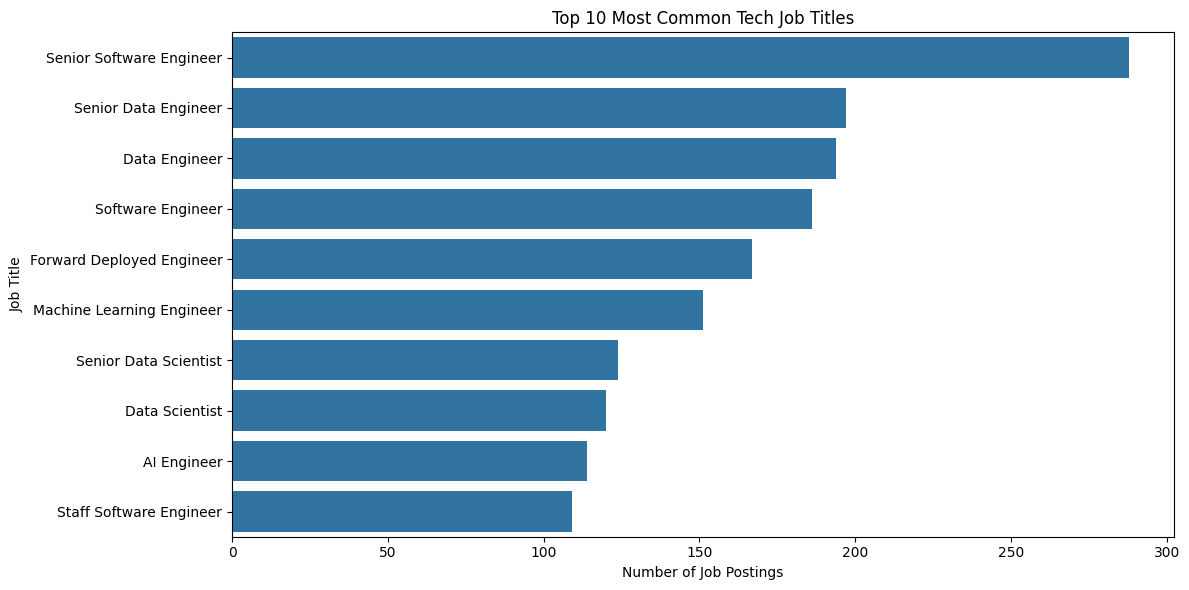

In [38]:
# Get top 10 job titles

top_jobs = df_english["job_title"].value_counts().head(10)

# Create bar chart

plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_jobs.values,
    y=top_jobs.index
)

plt.title("Top 10 Most Common Tech Job Titles")
plt.xlabel("Number of Job Postings")
plt.ylabel("Job Title")

plt.tight_layout()
plt.show()

## Most In-Demand Technical Skills

This section identifies the most frequently mentioned technical skills across job postings to help job seekers understand the skills required in the technology job market.

In [65]:
# Extract skills from all job postings

all_skills = []

for skills in df_english["required_skills"]:
    if isinstance(skills, (list, np.ndarray)):
        all_skills.extend(skills)
    elif isinstance(skills, str):
        all_skills.extend(skills.split(","))

# Count skill frequencies

skill_counts = Counter(all_skills)

top_skills = pd.DataFrame(
    skill_counts.most_common(10),
    columns=["Skill", "Job Postings"]
)

display(top_skills)

,Skill,Job Postings
0,python,29194
1,sql,10582
2,aws,9043
3,machine-learning,7691
4,communication,7573
5,ci-cd,6947
6,llm,6314
7,kubernetes,6040
8,data-engineering,5456
9,gcp,5096


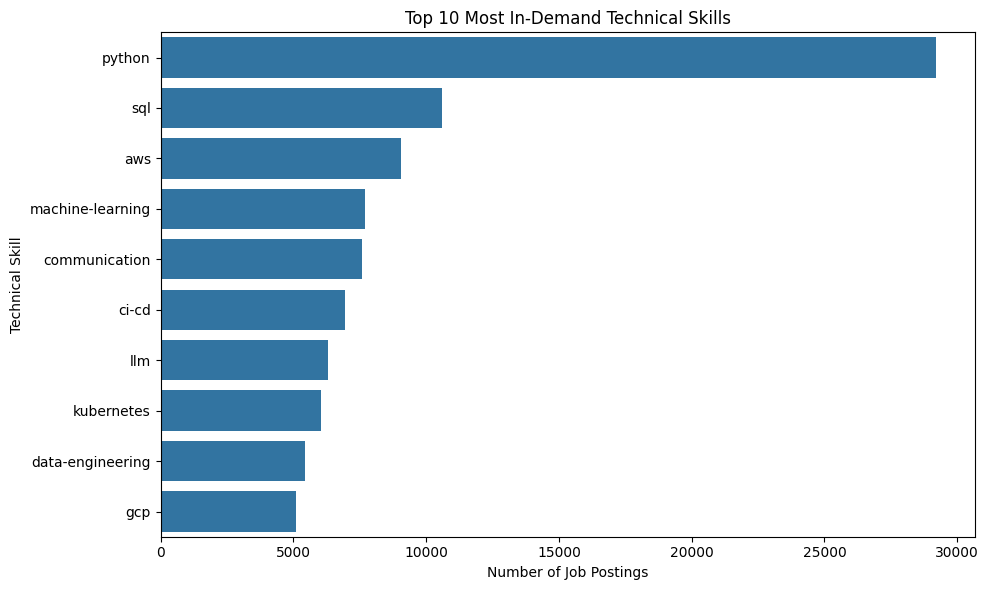

In [66]:
# Visualize top 10 technical skills

plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_skills,
    x="Job Postings",
    y="Skill"
)

plt.title("Top 10 Most In-Demand Technical Skills")
plt.xlabel("Number of Job Postings")
plt.ylabel("Technical Skill")

plt.tight_layout()
plt.show()

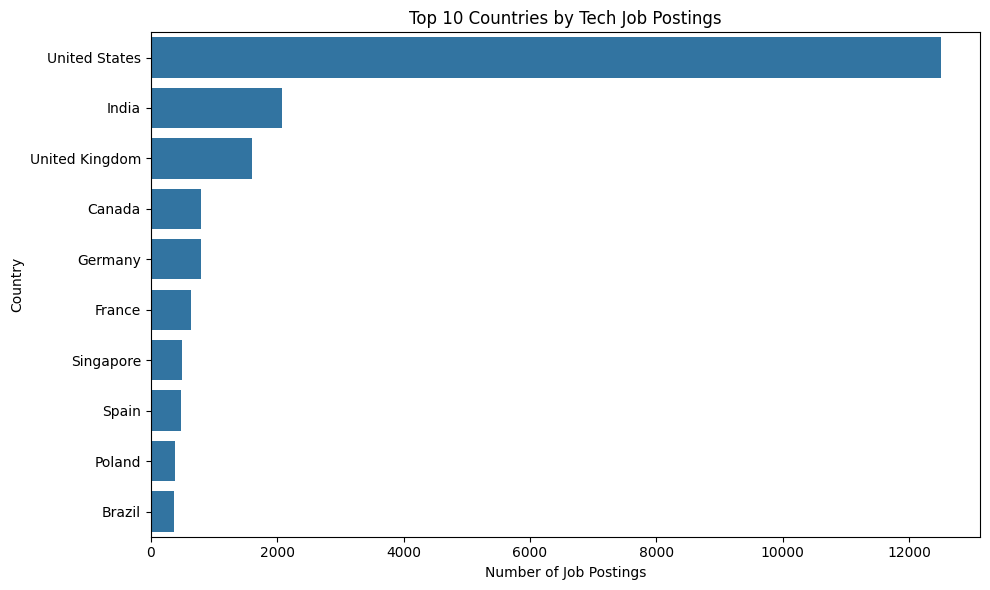

In [67]:
# Top 10 countries by job postings

top_countries = (
    df_english[df_english["country"] != "Unknown"]["country"]
    .value_counts()
    .head(10)
)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_countries.values,
    y=top_countries.index
)

plt.title("Top 10 Countries by Tech Job Postings")
plt.xlabel("Number of Job Postings")
plt.ylabel("Country")

plt.tight_layout()
plt.show()

In [68]:
# Salary data availability

salary_available = df_english["min_salary"].notna().sum()
salary_missing = df_english["min_salary"].isna().sum()

print("Jobs with salary information:", salary_available)
print("Jobs without salary information:", salary_missing)

# Salary records by currency

display(
    df_english["salary_currency"]
    .value_counts()
    .head(10)
)

Jobs with salary information: 13223
Jobs without salary information: 15971


,count
salary_currency,
USD,12239
EUR,437
GBP,223
CAD,191
PLN,36
INR,29
SGD,13
BRL,9
AUD,9


### Salary Analysis – Key Findings

- 13,223 job postings contain salary information.
- 15,971 job postings do not provide salary information.
- USD is the most frequently reported salary currency, followed by EUR and GBP.
- Salary comparisons require considering both currency and payment period.

**Key Insight:** More than half of the job postings do not disclose salary information, highlighting a limitation in salary transparency within this dataset.

### Key Findings – Exploratory Data Analysis

**1. Most Common Job Titles**
- Senior Software Engineer is the most frequently listed job title.
- Data Engineering and Software Engineering roles are highly represented.

**2. Most In-Demand Technical Skills**
- Python is the most frequently listed skill.
- SQL and AWS follow Python.
- Machine Learning, LLM, Kubernetes, and Data Engineering also appear among the top skills.

**3. Geographic Distribution**
- The United States has the highest number of job postings.
- India and the United Kingdom follow.

**4. Employment Type**
- Full-time positions represent the largest known employment category.

**5. Salary Transparency**
- More than half of the job postings do not include salary information.
- USD is the most frequently reported salary currency.

**Dataset Limitation:** The dataset is a snapshot of collected job postings, not a real-time representation of the entire global job market. Skill frequencies may also reflect the dataset's collection and preparation methodology.

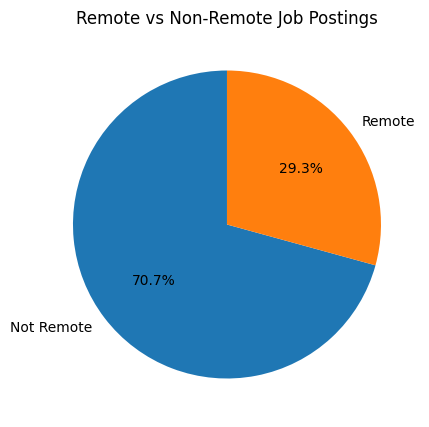

In [69]:
remote_counts = df_english["is_remote"].value_counts()

remote_labels = remote_counts.index.map({
    True: "Remote",
    False: "Not Remote"
})

plt.figure(figsize=(7, 5))

plt.pie(
    remote_counts.values,
    labels=remote_labels,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Remote vs Non-Remote Job Postings")
plt.show()

### Remote Work Analysis

- 29.3% of job postings are classified as remote.
- 70.7% are classified as non-remote.

**Key Insight:** Remote positions represent approximately 3 out of every 10 job postings in this dataset.

### EDA Conclusion

The exploratory analysis revealed several patterns in the collected technology job postings:

- Software Engineering and Data Engineering roles are highly represented.
- Python, SQL, and AWS are among the most frequently listed technical skills.
- The United States has the highest number of job postings.
- Full-time positions represent the largest known employment category.
- More than half of the postings do not disclose salary information.
- Approximately 29.3% of postings are classified as remote.

These findings will guide the design of the interactive dashboard.

In [95]:
import os

print("Dataset exists:", os.path.exists("tech_jobs_cleaned.csv"))

Dataset exists: True


In [96]:

%%writefile app.py
import ast
import re
from pathlib import Path

import pandas as pd
import plotly.express as px
import streamlit as st

st.set_page_config(page_title="Tech Job Market Insights", layout="wide")

TEAL = "#0F766E"
PURPLE = "#6D5BD0"
CSV_PATH = Path(__file__).with_name("tech_jobs_cleaned.csv")


def parse_skills(value):
    if not isinstance(value, str):
        return []

    tokens = re.findall(
        r"""'(?:\\.|[^'\\])*'|"(?:\\.|[^"\\])*" """.strip(),
        value
    )

    skills = []
    for token in tokens:
        try:
            skill = ast.literal_eval(token).strip()
            if skill:
                skills.append(skill)
        except (ValueError, SyntaxError):
            continue

    return list(dict.fromkeys(skills))


@st.cache_data
def load_jobs(path, modified_at):
    jobs = pd.read_csv(path, dtype="string", keep_default_na=False)

    for column in ["job_title", "country", "employment_type"]:
        jobs[column] = jobs[column].str.strip()

    jobs["skills"] = jobs["required_skills"].map(parse_skills)
    return jobs


def ranking_chart(counts, label, color, axis_title):
    chart_data = (
        counts.sort_values()
        .rename_axis(label)
        .reset_index(name="Postings")
    )

    fig = px.bar(
        chart_data,
        x="Postings",
        y=label,
        orientation="h",
        text="Postings",
        color_discrete_sequence=[color],
        template="plotly_white",
    )

    fig.update_traces(textposition="outside", cliponaxis=False)
    fig.update_layout(
        height=max(240, 36 * len(chart_data) + 80),
        margin=dict(l=12, r=30, t=16, b=45),
        font=dict(color="#1E293B", size=13),
        bargap=0.3,
    )

    if not counts.empty:
        fig.update_xaxes(
            title=axis_title,
            range=[0, counts.max() * 1.2],
            tickformat="d",
            gridcolor="#E8EDF3",
        )

    fig.update_yaxes(title=None, automargin=True)
    return fig


st.title("Tech Job Market Insights")
st.caption("Explore technology job postings, skills, and market trends.")

with st.sidebar:
    st.header("Dataset")
    st.markdown(
        "Technology job postings dataset.\n\n"
        "Snapshot: August 1, 2026.\n\n"
        "[View dataset on Hugging Face]"
        "(https://huggingface.co/datasets/zalizedata/tech-job-postings-salary-dataset)"
    )

if not CSV_PATH.is_file():
    st.error("Dataset file not found: tech_jobs_cleaned.csv")
    st.stop()

jobs = load_jobs(str(CSV_PATH), CSV_PATH.stat().st_mtime_ns)

with st.sidebar:
    st.header("Filters")

    countries = st.multiselect(
        "Country",
        sorted(jobs.loc[jobs["country"].ne(""), "country"].unique()),
        placeholder="All countries",
    )

    employment_types = st.multiselect(
        "Employment type",
        sorted(jobs.loc[jobs["employment_type"].ne(""), "employment_type"].unique()),
        placeholder="All employment types",
    )

if countries:
    jobs = jobs.loc[jobs["country"].isin(countries)]

if employment_types:
    jobs = jobs.loc[jobs["employment_type"].isin(employment_types)]

if jobs.empty:
    st.info("No postings match these filters.")
    st.stop()

title_counts = jobs.loc[
    jobs["job_title"].ne(""), "job_title"
].value_counts()

has_skills = jobs["skills"].map(bool)

total, top_title, coverage = st.columns([1, 2, 1])

total.metric("Job postings", f"{len(jobs):,}")
top_title.metric(
    "Most common job title",
    title_counts.index[0] if not title_counts.empty else "—"
)
coverage.metric("Postings with recorded skills", f"{has_skills.mean():.0%}")

overview_tab, skills_tab, data_tab = st.tabs(
    ["Market Overview", "Skills Explorer", "Job Postings"]
)

with overview_tab:
    st.subheader("Top 10 Job Titles")

    if not title_counts.empty:
        st.plotly_chart(
            ranking_chart(
                title_counts.head(10),
                "Job title",
                TEAL,
                "Number of postings",
            ),
            use_container_width=True,
        )

    st.subheader("Top 10 Countries")
    country_counts = jobs.loc[
        jobs["country"].ne("Unknown"), "country"
    ].value_counts().head(10)

    if not country_counts.empty:
        st.plotly_chart(
            ranking_chart(
                country_counts,
                "Country",
                PURPLE,
                "Number of postings",
            ),
            use_container_width=True,
        )

    st.subheader("Remote Work Distribution")

    if "is_remote" in jobs.columns:
        remote_values = jobs["is_remote"].astype(str).str.lower()
        remote_counts = remote_values.map(
            {"true": "Remote", "false": "Non-Remote"}
        ).value_counts()

        if not remote_counts.empty:
            fig = px.pie(
                names=remote_counts.index,
                values=remote_counts.values,
                hole=0.45,
                template="plotly_white",
            )
            st.plotly_chart(fig, use_container_width=True)

with skills_tab:
    st.subheader("Top Skills by Job Title")

    if not title_counts.empty:
        available_titles = title_counts.index.tolist()

        default_index = (
            available_titles.index("AI Engineer")
            if "AI Engineer" in available_titles else 0
        )

        selected_title = st.selectbox(
            "Choose a job title",
            available_titles,
            index=default_index,
        )

        role_jobs = jobs.loc[jobs["job_title"].eq(selected_title)]
        recorded_skills = role_jobs.loc[
            role_jobs["skills"].map(bool), "skills"
        ]

        st.caption(
            f"{len(role_jobs):,} matching postings · "
            f"{len(recorded_skills):,} with recorded skills"
        )

        if not recorded_skills.empty:
            top_skills = (
                recorded_skills.explode().value_counts().head(10)
            )

            st.plotly_chart(
                ranking_chart(
                    top_skills,
                    "Skill",
                    PURPLE,
                    "Number of postings mentioning the skill",
                ),
                use_container_width=True,
            )
        else:
            st.info("No skills recorded for this job title.")

with data_tab:
    st.subheader("Job Postings Preview")

    preview_columns = [
        col for col in [
            "job_title", "company", "country",
            "employment_type", "is_remote",
            "min_salary", "max_salary"
        ]
        if col in jobs.columns
    ]

    preview = jobs[preview_columns].head(20)
    st.dataframe(preview, hide_index=True, use_container_width=True)

    st.caption(
        f"Showing {len(preview):,} of {len(jobs):,} matching postings."
    )


Overwriting app.py


In [97]:
import subprocess
import time

with open("streamlit.log", "w") as log:
    process = subprocess.Popen(
        [
            "streamlit", "run", "app.py",
            "--server.port=8502",
            "--server.address=0.0.0.0",
            "--server.headless=true"
        ],
        stdout=log,
        stderr=subprocess.STDOUT
    )

time.sleep(5)
print("Running:", process.poll() is None)

with open("streamlit.log") as log:
    print(log.read())

Running: False


2026-11-14 20:53:42.658 Port 8502 is not available



In [99]:
import psutil

for p in psutil.process_iter(["pid", "cmdline"]):
    try:
        cmd = " ".join(p.info["cmdline"] or [])
        if "streamlit" in cmd and "app.py" in cmd:
            print("Stopping:", p.info["pid"])
            p.terminate()
    except (psutil.NoSuchProcess, psutil.AccessDenied):
        pass

Stopping: 10630
Stopping: 13908


In [100]:
import subprocess
import time

with open("streamlit.log", "w") as log:
    process = subprocess.Popen(
        [
            "streamlit", "run", "app.py",
            "--server.port=8503",
            "--server.address=0.0.0.0",
            "--server.headless=true"
        ],
        stdout=log,
        stderr=subprocess.STDOUT
    )

time.sleep(5)

print("Running:", process.poll() is None)

with open("streamlit.log") as log:
    print(log.read())

Running: True


2026-11-14 20:55:16.913 Uvicorn server started on 0.0.0.0:8503

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8503
  Network URL: http://172.28.0.12:8503
  External URL: http://34.86.53.211:8503




In [102]:
import requests

try:
    response = requests.get("http://127.0.0.1:8503", timeout=15)
    print("Status:", response.status_code)
    print("Response:", response.text[:500])
except Exception as e:
    print("Connection error:", e)

Status: 200
Response: <!--
 Copyright (c) Streamlit Inc. (2018-2022) Snowflake Inc. (2022-2026)

 Licensed under the Apache License, Version 2.0 (the "License");
 you may not use this file except in compliance with the License.
 You may obtain a copy of the License at

     http://www.apache.org/licenses/LICENSE-2.0

 Unless required by applicable law or agreed to in writing, software
 distributed under the License is distributed on an "AS IS" BASIS,
 WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or im


In [104]:
from google.colab import output
from IPython.display import HTML, display

url = output.eval_js("google.colab.kernel.proxyPort(8503)")

display(HTML(
    f'<a href="{url}" target="_blank" '
    'style="font-size:20px;">Open Tech Job Market Dashboard</a>'
))

In [105]:
!wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64.deb
!dpkg -i cloudflared-linux-amd64.deb

Selecting previously unselected package cloudflared.
(Reading database ... 122813 files and directories currently installed.)
Preparing to unpack cloudflared-linux-amd64.deb ...
Unpacking cloudflared (2026.11.0) ...
Setting up cloudflared (2026.11.0) ...
Processing triggers for man-db (2.12.0-4build2) ...


In [106]:
import subprocess
import time

tunnel = subprocess.Popen(
    ["cloudflared", "tunnel", "--url", "http://localhost:8503"],
    stdout=open("tunnel.log", "w"),
    stderr=subprocess.STDOUT
)

time.sleep(10)

with open("tunnel.log") as f:
    print(f.read())

2026-11-14T21:02:13Z INF Thank you for trying Cloudflare Tunnel. Doing so, without a Cloudflare account, is a quick way to experiment and try it out. However, be aware that these account-less Tunnels have no uptime guarantee, are subject to the Cloudflare Online Services Terms of Use (https://www.cloudflare.com/website-terms/), and Cloudflare reserves the right to investigate your use of Tunnels for violations of such terms. If you intend to use Tunnels in production you should use a pre-created named tunnel by following: https://developers.cloudflare.com/cloudflare-one/connections/connect-apps
2026-11-14T21:02:13Z INF Requesting new quick Tunnel on trycloudflare.com...
2026-11-14T21:02:17Z INF +--------------------------------------------------------------------------------------------+
2026-11-14T21:02:17Z INF |  Your quick Tunnel has been created! Visit it at (it may take some time to be reachable):  |
2026-11-14T21:02:17Z INF |  https://maine-chris-folder-chapel.trycloudflare.com  

In [107]:
from google.colab import files

files.download("app.py")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [108]:
files.download("tech_jobs_cleaned.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>